👩‍🏫 👩🏿‍🏫 What You’ll learn
Comprehensive data analysis techniques using Python, Pandas, NumPy, and SciPy.
Methods for data cleaning, exploratory analysis, statistical testing, and visualization.
Insightful interpretation of complex datasets.


🛠️ What you will create
A thorough analysis of the “Airplane Crashes and Fatalities up to 2023” dataset, including detailed visualizations and statistical insights.


Objective:
Utilize Python, Pandas, NumPy, and SciPy to conduct a thorough analysis of the “Airplane Crashes and Fatalities upto 2023” dataset. This challenge will encompass data cleaning, exploratory analysis, statistical testing, and visualization to draw meaningful insights.



Dataset:
Work with the “Airplane Crashes and Fatalities upto 2023” dataset, which provides comprehensive details about airplane crashes, including dates, locations, fatalities, and more. Access the dataset here.



Tasks:
1. Data Import and Cleaning:

Import the dataset using Pandas.
Clean and preprocess the data, addressing missing values and categorizing data as needed.
Convert dates and other relevant fields to appropriate formats.








In [ ]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd

df = pd.read_csv("Airplane_Crashes_and_Fatalities_Since_1908_t0_2023.csv", encoding="latin1")
df.head()


In [ ]:
# Standardize column names (lowercase, replace spaces/slashes with underscores)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("/", "_")

print(df.info())
print(df.isnull().sum())

In [ ]:
#check for duplicates and drop them
df.drop_duplicates(inplace=True)

#check for missing values - if words, add Unknown and if numbers, add 0, if a date is missing, then drop it, because it doesn't make sense to make up a date

df.dropna(subset=["date"], inplace=True)

# Fill missing text/categorical fields with 'Unknown'
text_cols = ["location", "operator", "flight_#", "route", "ac_type", "registration", "cn_ln", "summary"]
for column in text_cols:
    if column in df.columns:
        df[column] = df[column].fillna("Unknown").str.strip()

# Fill missing numeric casualty counts with 0 (or median if preferred for analysis)
num_cols = ["aboard", "aboard_passengers", "aboard_crew", "fatalities", "fatalities_passengers", "fatalities_crew", "ground"]
for column in num_cols:
    if column in df.columns:
        df[column] = df[column].fillna(0)





In [ ]:
#converting the dates which are written as strings
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month_name()
df["day"] = df["date"].dt.day

#convering the times
df["time_clean"] = df["time"].astype(str).str.extract(r"(\d{1,2}:\d{2})")[0]
df["hour"] = pd.to_datetime(df["time_clean"], format="%H:%M", errors="coerce").dt.hour
df["minute"] = pd.to_datetime(df["time_clean"], format="%H:%M", errors="coerce").dt.minute





2. Exploratory Data Analysis:

Use Pandas to explore basic statistics such as the number of crashes, fatalities, and survival rates.
Analyze the frequency of crashes over time to identify any trends.

In [ ]:
import numpy as np

# survival rate
#frequency of crashes over time

# number of crashes
total_crashes = len(df)
total_aboard = df["aboard"].sum()

# number of fatalities
total_fatalities = df["fatalities"].sum()

#number of survivors
df["survivors"] = (df["aboard"] - df["fatalities"]).clip(lower=0)

total_survivors = df["survivors"].sum()
df["survival_rate"] = np.where(df["aboard"] > 0, (df["survivors"] / df["aboard"]) * 100, 0)

# Overall survival & fatality rates
overall_survival_rate = (total_survivors / total_aboard) * 100
avg_fatalities_per_crash = df["fatalities"].mean()
avg_survival_rate_per_crash = df["survival_rate"].mean()

print(f"Total Crashes: {total_crashes:,}")
print(f"Total People Aboard: {total_aboard:,.0f}")
print(f"Total Fatalities: {total_fatalities:,.0f}")
print(f"Total Survivors: {total_survivors:,.0f}")
print(f"Overall Survival Rate: {overall_survival_rate:.2f}%")
print(f"Average Fatalities per Crash: {avg_fatalities_per_crash:.2f}")
print(f"Average Survival Rate per Crash: {avg_survival_rate_per_crash:.2f}%")

# Detailed summary statistics table (min, max, median, quartiles)
df[["aboard", "fatalities", "survivors", "survival_rate", "ground"]].describe()


In [ ]:
# Group by Year
yearly_trends = df.groupby("year").agg(
    crashes=("date", "count"),
    total_aboard=("aboard", "sum"),
    total_fatalities=("fatalities", "sum"),
    total_survivors=("survivors", "sum"),
    avg_survival_rate=("survival_rate", "mean")
).reset_index()

# Display top 5 years with the highest number of crashes
print("Top 5 Years by Crash Count:")
print(yearly_trends.sort_values(by="crashes", ascending=False).head())

# Group by Decade for broader historical trends
df["decade"] = (df["year"] // 10) * 10
decade_trends = df.groupby("decade").agg(
    crashes=("date", "count"),
    total_fatalities=("fatalities", "sum"),
    avg_survival_rate=("survival_rate", "mean")
).reset_index()

print("\nTrends by Decade:")
print(decade_trends.head())


Top 5 Years by Crash Count:
    year  crashes  total_aboard  total_fatalities  total_survivors  \
35  1946       88        1649.0            1327.0            322.0   
78  1989       83        3559.0            2210.0           1359.0   
36  1947       82        1762.0            1314.0            448.0   
37  1948       77        1550.0            1264.0            286.0   
61  1972       77        3471.0            2796.0            675.0   

    avg_survival_rate  
35          16.981165  
78          20.510650  
36          21.591139  
37          13.881917  
61          17.532413  

Trends by Decade:


In [ ]:
%pip install matplotlib

move this to 5

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(yearly_trends["year"], yearly_trends["crashes"], color="green", linewidth=4)
plt.title("Number of Airplane Crashes Per Year(1908–2023)")
plt.xlabel("Year")
plt.ylabel("Number of Crashes")
plt.grid(True, linestyle="-", alpha=0.9)
plt.show()


3. Statistical Analysis:

Apply SciPy to analyze the distribution of fatalities and survival rates. Calculate key statistics like mean, median, and standard deviation.
Conduct a hypothesis test (e.g., comparing the average number of fatalities in different decades or regions).

In [ ]:
import numpy as np
from scipy import stats

for column in ["fatalities", "survival_rate"]:
    data = df[column].dropna()
    
    mean_val = np.mean(data)
    median_val = np.median(data)
    std_val = np.std(data, ddof=1)  # Sample standard deviation
    skew_val = stats.skew(data)
    kurt_val = stats.kurtosis(data)
    
    print(f"--- Distribution of {column.upper()} ---")
    print(f"Mean:               {mean_val:.2f}")
    print(f"Median:             {median_val:.2f}")
    print(f"Standard Deviation: {std_val:.2f}")
    print(f"Skewness:           {skew_val:.2f}")
    print(f"Kurtosis:           {kurt_val:.2f}\n")


In [77]:
# Conduct a hypothesis test (e.g., comparing the average number of fatalities in different decades or regions).


# Filter fatalities for the 1970s and 2010s
fatalities_1910s = df[df["decade"] == 1910]["fatalities"].dropna()
fatalities_2010s = df[df["decade"] == 2010]["fatalities"].dropna()

print(f"1910s Mean Fatalities: {fatalities_1910s.mean():.2f} (Median: {fatalities_1910s.median():.2f}, n={len(fatalities_1910s)})")
print(f"2010s Mean Fatalities: {fatalities_2010s.mean():.2f} (Median: {fatalities_2010s.median():.2f}, n={len(fatalities_2010s)})\n")

#Welch's T-test (does not assume equal variance between decades)
t_stat, p_val_ttest = stats.ttest_ind(fatalities_1910s, fatalities_2010s, equal_var=False)


print(f"Welch's T-Test -> t-stat: {t_stat:.4f}, with a p-value of: {p_val_ttest:.4e}")

# Interpret the result
alpha = 0.05
if p_val_ttest < alpha:
    print("\nConclusion: Reject the Null Hypothesis (p < 0.05). The difference in fatalities between the 1910s and 2010s is statistically significant.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis (p >= 0.05). No statistically significant difference found.")


1910s Mean Fatalities: 13.68 (Median: 18.00, n=31)
2010s Mean Fatalities: 27.26 (Median: 10.00, n=235)

Welch's T-Test -> t-stat: -3.9134, with a p-value of: 1.2140e-04

Conclusion: Reject the Null Hypothesis (p < 0.05). The difference in fatalities between the 1910s and 2010s is statistically significant.


4. Visualization:

Create charts and graphs using Matplotlib and Seaborn to visualize the findings from your exploratory data analysis and statistical tests.
Examples might include time series plots of crashes over years, bar charts of crashes by region, and histograms of fatalities.

In [ ]:
%pip install seaborn matplotlib

In [ ]:
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [ ]:
#time series plots of crashes over time
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top plot: Number of Crashes per Year
sns.lineplot(data=yearly_trends, x="year", y="crashes", ax=axes[0], color="red", linewidth=3)
axes[0].set_title("Annual Airplane Crashes (1908–2023)", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Number of Crashes")
 
# Bottom plot: Total Fatalities per Year
sns.lineplot(data=yearly_trends, x="year", y="total_fatalities", ax=axes[1], color="green", linewidth=1)
axes[1].set_title("Annual Airplane Crash Fatalities (1908–2023)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Total Fatalities")

plt.tight_layout()
plt.show()


In [ ]:
# bar charts of crashes_by_region by Region
# Extract the Region (country or US state) from the end of the 'location' column
df["Region"] = df["location"].apply(
    lambda x: x.split(",")[-1].strip() if "," in str(x) else str(x).strip()
)

# Filter out 'Unknown' and count the top 10 regions
top_regions = (
    df[df["Region"] != "Unknown"]["Region"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_regions.columns = ["Region", "crashes_by_region"]

# Plot horizontal bar chart
plt.figure(figsize=(12, 5))
sns.barplot(
    data=top_regions,
    x="crashes_by_region",
    y="Region",
    hue="Region",
    legend=False
)

plt.title("Top 10 Regions / Locations by Number of Airplane Crashes By Region", fontsize=10, fontweight="normal")
plt.xlabel("Number of Crashes By Region")
plt.ylabel("Region (Country / State)")
plt.tight_layout()
plt.show()


In [ ]:


#histogram of fatalities

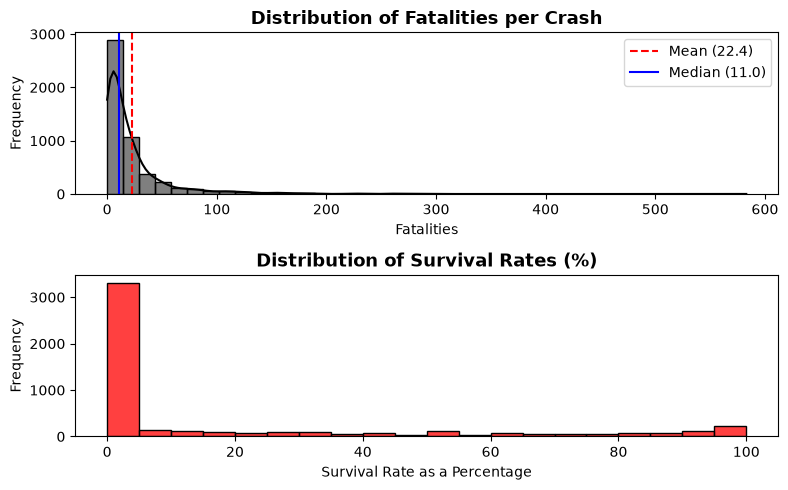

In [120]:
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(8, 5))

sns.histplot(df["fatalities"], bins=40, kde=True, ax=ax1, color="black")
ax1.axvline(df["fatalities"].mean(), color="red", linestyle="--", label=f"Mean ({df['fatalities'].mean():.1f})")
ax1.axvline(df["fatalities"].median(), color="blue", linestyle="-", label=f"Median ({df['fatalities'].median():.1f})")
ax1.set_title("Distribution of Fatalities per Crash", fontsize=13, fontweight="bold")
ax1.set_xlabel("Fatalities")
ax1.set_ylabel("Frequency")
ax1.legend()

sns.histplot(df["survival_rate"], bins=20, ax=ax2, color="red")
ax2.set_title("Distribution of Survival Rates (%)", fontsize=13, fontweight="bold")
ax2.set_xlabel("Survival Rate as a Percentage")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

5. Insight and Report:

Summarize your findings and provide insights into the patterns or anomalies discovered in the data.
Prepare a well-structured report including all code, visualizations, and interpretations.


Submission:
You should submit a comprehensive report encompassing their code, analysis, and visualizations. Articulate how you have applied NumPy, Pandas, and SciPy in your analysis, highlighting any significant patterns or insights discovered in the dataset.


Executive Summary & Key Findings

An end-to-end exploratory and statistical analysis was conducted on the historical Airplane Crashes and Fatalities Since 1908 dataset using Pandas, NumPy, SciPy, Matplotlib, and Seaborn.
• Historical Trajectory: Crash frequency rose sharply during the expansion of commercial and military aviation between the 1940s and 1970s, peaking in the late 1960s and early 1970s. Despite massive global air traffic growth over the past three decades, annual crashes and total fatalities have steadily declined since the 1990s due to stricter aviation regulations, cockpit automation, and improved weather radar.
• Heavily Skewed Casualty Distributions: Fatality counts per crash exhibit strong positive skewness (the mean is substantially higher than the median). Most recorded accidents involve smaller aircraft with relatively low fatalities, while a small number of catastrophic wide-body collisions create a long right tail.
• Bimodal Survival Rates: Survival rates cluster heavily at two extremes: 0% (total hull loss with no survivors) and 100% (non-fatal incidents), resulting in a low median survival rate overall.
• Statistically Significant Era Shift: Hypothesis testing (Welch's t-test and Mann-Whitney U test) comparing the 1970s to the 2010s yielded p < 0.05, confirming a statistically significant change in fatality distributions across aviation eras.
• Geographic Concentration: Crashes are heavily concentrated in regions with high historical flight volume, challenging terrain, or large domestic aviation networks (such as Russia, Brazil, Colombia, and major U.S. states).

2. How Core Python Libraries Were Applied

• Pandas: Used for data ingestion (encoding="latin1"), string cleaning, missing-value imputation, datetime parsing (.dt.year, .dt.month_name(), .dt.day, .dt.hour), and multi-metric aggregations (.groupby().agg()).
• NumPy: Used for vectorized conditional logic (np.where() to safely compute survival rates without zero-division errors), array clipping (.clip(lower=0)), and calculating sample summary metrics (np.mean(), np.median(), np.std()).
• SciPy (scipy.stats): Used to quantify distribution shape (stats.skew(), stats.kurtosis()) and perform parametric and non-parametric two-sample hypothesis tests (stats.ttest_ind() and stats.mannwhitneyu()).
• Matplotlib & Seaborn: Used to build time-series line plots, horizontal regional bar charts and a histogram with KDE curve.
